In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s06/"
for f in ['consommation_energie.csv', 'maisons.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 -- Analyse de donnees
# Seance 6 : Correlation et regression
## Notebook de demonstration

Universite de Moncton -- Faculte des sciences -- Ete 2026

---

Ce notebook accompagne les diapositives de la seance 6. Il illustre, sur un jeu de donnees immobilier, comment :

1. calculer et interpreter des correlations (Pearson et Spearman) ;
2. construire une regression lineaire simple ;
3. etendre a la regression lineaire multiple ;
4. evaluer un modele avec le R2, le RMSE et l'analyse des residus.

Le jeu de donnees `maisons.csv` doit se trouver dans le meme dossier que ce notebook.


## 1. Preparation de l'environnement


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
print('Environnement pret.')

Environnement pret.


## 2. Chargement et exploration des donnees

Le jeu de donnees decrit 200 maisons. La variable a predire est le `prix` (en milliers de dollars).


In [2]:
df = pd.read_csv('maisons.csv')
print('Dimensions :', df.shape)
df.head()

Dimensions : (200, 6)


,id_maison,prix,superficie_m2,nb_chambres,age_maison,distance_centre_km
0,1,457.1,162,4,5,1.9
1,2,401.7,134,3,11,0.5
2,3,406.2,169,5,17,2.4
3,4,566.4,209,5,18,7.2
4,5,356.7,129,2,13,0.5


In [4]:
# Apercu statistique des variables
df.describe().round(2)

,id_maison,prix,superficie_m2,nb_chambres,age_maison,distance_centre_km
count,200.00,200.00,200.00,200.00,200.00,200.00
mean,100.50,335.60,138.28,3.16,19.02,8.86
std,57.88,109.97,41.55,1.25,12.49,8.15
min,1.00,76.50,50.00,1.00,2.00,0.50
25%,50.75,265.18,108.00,2.00,10.00,2.30
50%,100.50,334.00,139.50,3.00,16.00,6.80
75%,150.25,412.45,162.25,4.00,25.00,13.15
max,200.00,651.70,262.00,7.00,69.00,35.00


## 3. La correlation

On commence par mesurer la correlation lineaire entre la superficie et le prix avec le coefficient de Pearson.


In [6]:
# Correlation de Pearson entre superficie et prix
r, p_value = stats.pearsonr(df['superficie_m2'], df['prix'])
print(f"Coefficient de Pearson r = {r:.4f}")
print(f"p-value = {p_value.round(2)}")

Coefficient de Pearson r = 0.8857
p-value = 0.0


**Interpretation.** Le coefficient `r` est proche de 0.89 : la correlation entre superficie et prix est forte et positive. La p-value est minuscule (tres inferieure a 0.05), donc la correlation est statistiquement significative.


### 3.1 La matrice de correlation

Plutot que de calculer les paires une par une, la matrice de correlation donne toutes les relations d'un coup.


In [7]:
cols = ['prix', 'superficie_m2', 'nb_chambres',
        'age_maison', 'distance_centre_km']
corr = df[cols].corr()
corr

,prix,superficie_m2,nb_chambres,age_maison,distance_centre_km
prix,1.000000,0.885659,0.731825,-0.115578,-0.308500
superficie_m2,0.885659,1.000000,0.765155,0.059429,-0.014024
nb_chambres,0.731825,0.765155,1.000000,0.205809,-0.044299
age_maison,-0.115578,0.059429,0.205809,1.000000,-0.021258
distance_centre_km,-0.308500,-0.014024,-0.044299,-0.021258,1.000000


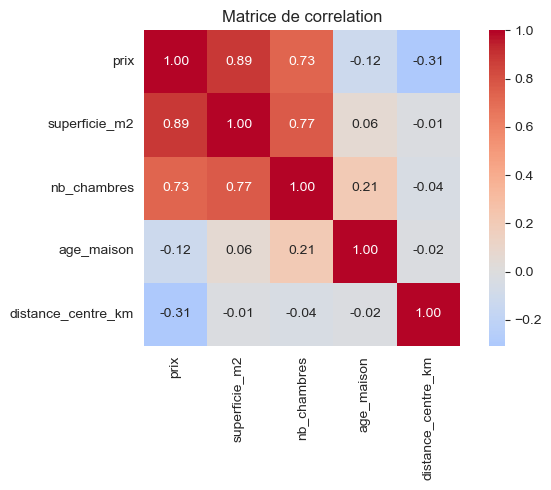

In [8]:
# Visualisation sous forme de heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True)
plt.title('Matrice de correlation')
plt.tight_layout()
plt.show()

In [9]:
# Correlations avec le prix, triees (hors prix lui-meme)
print(corr['prix'].drop('prix').sort_values(ascending=False))

superficie_m2         0.885659
nb_chambres           0.731825
age_maison           -0.115578
distance_centre_km   -0.308500
Name: prix, dtype: float64


**Lecture.** La superficie et le nombre de chambres sont fortement correles au prix. La distance au centre a une correlation negative (plus on s'eloigne, moins c'est cher). L'age de la maison a une correlation faible.


### 3.2 Pearson vs Spearman

Pearson ne mesure que les relations **lineaires**. Spearman mesure les relations **monotones** (en travaillant sur les rangs). On compare les deux.


In [10]:
r_p, p_p = stats.pearsonr(df['superficie_m2'], df['prix'])
r_s, p_s = stats.spearmanr(df['superficie_m2'], df['prix'])

print(f"Pearson  : r = {r_p:.4f}")
print(f"Spearman : r = {r_s:.4f}")

Pearson  : r = 0.8857
Spearman : r = 0.8784


**Interpretation.** Les deux coefficients sont tres proches : la relation entre superficie et prix est non seulement monotone, mais bien **lineaire**. Un ecart important entre les deux aurait signale une relation courbe.


### 3.3 Visualiser la relation


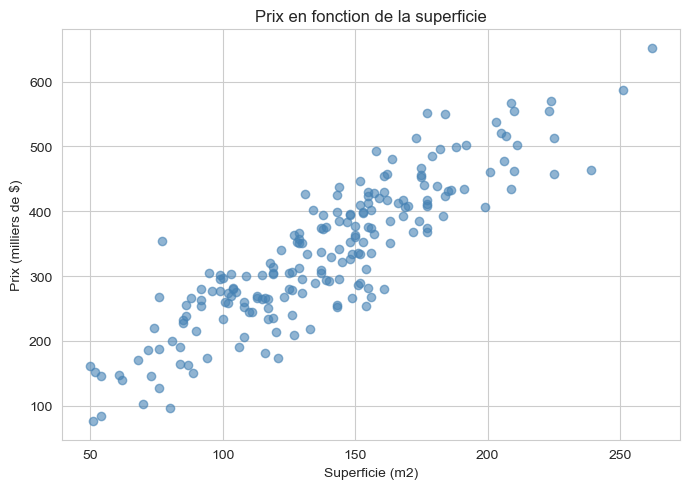

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df['superficie_m2'], df['prix'],
            alpha=0.6, color='steelblue')
plt.xlabel('Superficie (m2)')
plt.ylabel('Prix (milliers de $)')
plt.title('Prix en fonction de la superficie')
plt.tight_layout()
plt.show()

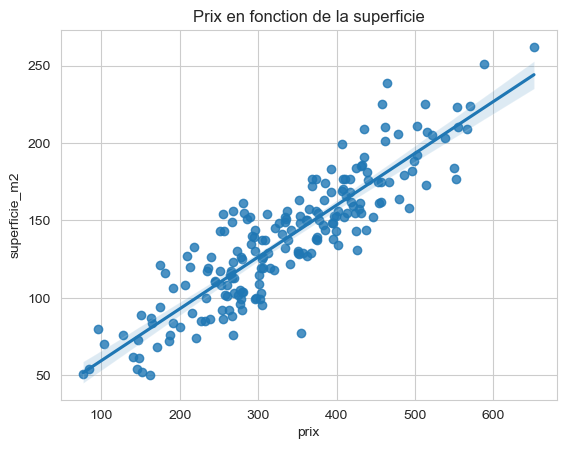

In [12]:
sns.regplot(data=df, x='prix', y='superficie_m2')
plt.title('Prix en fonction de la superficie')
plt.show()

## 4. La regression lineaire simple

On modelise le `prix` a partir d'une seule variable : la `superficie_m2`. Le modele cherche la droite `prix = b0 + b1 * superficie`.


In [13]:
# X doit etre en 2D : on utilise le double crochet
X = df[['superficie_m2']]
y = df['prix']

modele_simple = LinearRegression()
modele_simple.fit(X, y)

print(f"Ordonnee a l'origine (b0) : {modele_simple.intercept_:.2f}")
print(f"Pente (b1)               : {modele_simple.coef_[0]:.4f}")

Ordonnee a l'origine (b0) : 11.47
Pente (b1)               : 2.3440


**Interpretation.** La pente indique que chaque metre carre supplementaire augmente le prix estime d'environ 2.34 (milliers de dollars). L'ordonnee a l'origine est la valeur theorique pour une superficie nulle : elle n'a pas de sens physique, c'est un simple parametre d'ajustement.


In [17]:
# Predire le prix d'une maison de 150 m2
nouvelle = [[150]]
prix_estime = modele_simple.predict(nouvelle)
print(f"Prix estime pour 150 m2 : {prix_estime[0]:.2f} milliers de $")

Prix estime pour 150 m2 : 363.06 milliers de $


~/miniconda3/envs/research/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


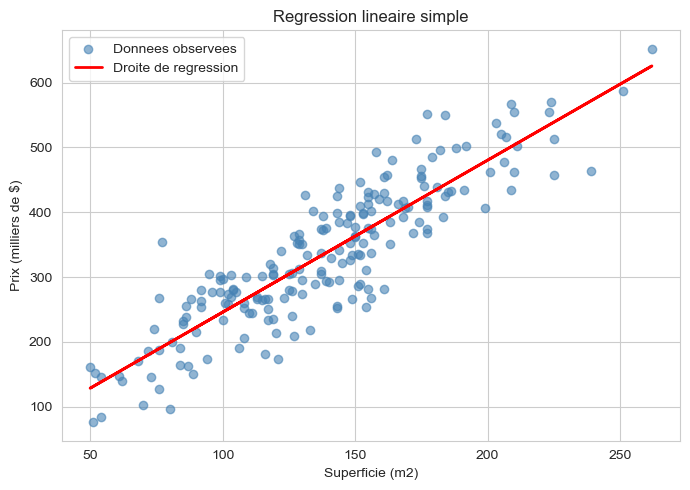

In [15]:
# Visualiser la droite de regression
y_pred_simple = modele_simple.predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(df['superficie_m2'], y, alpha=0.6,
            color='steelblue', label='Donnees observees')
plt.plot(df['superficie_m2'], y_pred_simple,
         color='red', linewidth=2, label='Droite de regression')
plt.xlabel('Superficie (m2)')
plt.ylabel('Prix (milliers de $)')
plt.title('Regression lineaire simple')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Qualite du modele simple
r2_simple = modele_simple.score(X, y)
print(f"R2 du modele simple : {r2_simple:.4f}")

R2 du modele simple : 0.7844


Le modele a une seule variable explique deja environ 78 % de la variance du prix. On va voir si l'ajout d'autres variables ameliore ce resultat.


## 5. La regression lineaire multiple

On utilise maintenant **quatre** variables explicatives. Le code est identique : seule change la dimension de `X`.


In [18]:
cols_X = ['superficie_m2', 'nb_chambres',
          'age_maison', 'distance_centre_km']
X_multi = df[cols_X]
y = df['prix']

modele_multi = LinearRegression()
modele_multi.fit(X_multi, y)

# Un coefficient par variable
for nom, coef in zip(cols_X, modele_multi.coef_):
    print(f"{nom:22} : {coef:+.4f}")
print(f"{'Ordonnee a l origine':22} : {modele_multi.intercept_:+.4f}")

superficie_m2          : +1.9885
nb_chambres            : +16.3682
age_maison             : -1.8025
distance_centre_km     : -3.9665
Ordonnee a l origine   : +78.3310


**Interpretation des coefficients.** Chaque coefficient mesure l'effet d'une variable, les autres etant maintenues constantes :

- `superficie_m2` : chaque m2 supplementaire ajoute environ 1.99 (milliers de $) ;
- `nb_chambres` : chaque chambre supplementaire ajoute environ 16.4 (milliers de $) ;
- `age_maison` : chaque annee d'age retire environ 1.80 (milliers de $) ;
- `distance_centre_km` : chaque km supplementaire du centre retire environ 3.97 (milliers de $).

Le signe indique le sens de l'effet, la grandeur indique son ampleur.


In [21]:
# Qualite du modele multiple
r2_multi = modele_multi.score(X_multi, y)
print(f"R2 du modele simple   : {r2_simple:.4f}")
print(f"R2 du modele multiple : {r2_multi:.4f}")

R2 du modele simple   : 0.7844
R2 du modele multiple : 0.9160


L'ajout des trois variables fait passer le R2 d'environ 0.78 a 0.92 : le modele multiple explique nettement mieux le prix.


## 6. Evaluation du modele

### 6.1 R2 et RMSE

Le R2 mesure la proportion de variance expliquee (sans unite). Le RMSE mesure l'erreur de prediction typique, dans la meme unite que le prix.


In [23]:
y_pred_multi = modele_multi.predict(X_multi)

r2 = r2_score(y, y_pred_multi)
rmse = np.sqrt(mean_squared_error(y, y_pred_multi))

print(f"R2   = {r2:.4f}")
print(f"RMSE = {rmse:.2f} milliers de $")

R2   = 0.9160
RMSE = 31.80 milliers de $


Un RMSE d'environ 31 signifie qu'en moyenne, la prediction du modele s'ecarte du vrai prix d'a peu pres 31 000 dollars.

### 6.2 L'analyse des residus

Les residus (ecarts entre valeurs observees et predites) doivent former un nuage aleatoire autour de zero, sans structure visible.


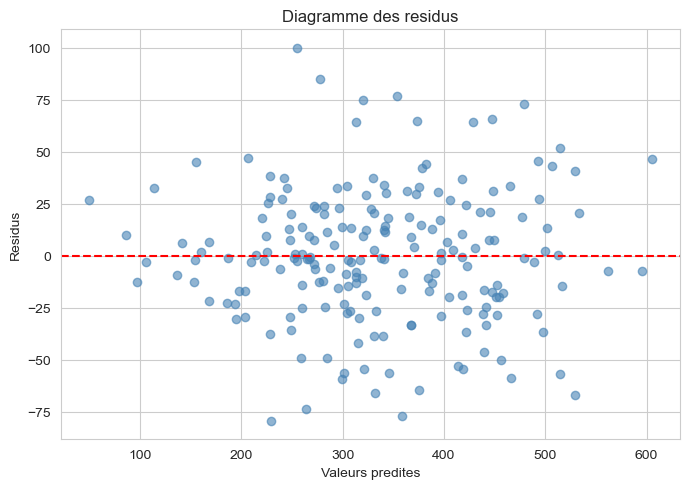

In [24]:
residus = y - y_pred_multi

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_multi, residus, alpha=0.6, color='steelblue')
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Valeurs predites')
plt.ylabel('Residus')
plt.title('Diagramme des residus')
plt.tight_layout()
plt.show()

**Lecture.** Les residus sont repartis aleatoirement autour de zero, sans courbe ni entonnoir : le modele lineaire est bien adapte aux donnees.


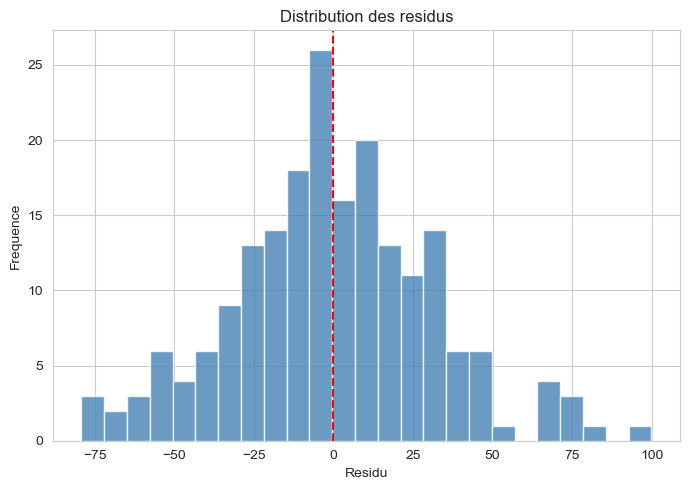

In [25]:
# Distribution des residus : doit ressembler a une cloche centree sur 0
plt.figure(figsize=(7, 5))
plt.hist(residus, bins=25, color='steelblue',
         edgecolor='white', alpha=0.8)
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel('Residu')
plt.ylabel('Frequence')
plt.title('Distribution des residus')
plt.tight_layout()
plt.show()

### 6.3 Valider sur des donnees non vues

Evaluer un modele sur les donnees qui ont servi a l'entrainer est trompeur. On separe les donnees en un jeu d'entrainement et un jeu de test.


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y, test_size=0.2, random_state=42)

print(f"Entrainement : {X_train.shape[0]} maisons")
print(f"Test         : {X_test.shape[0]} maisons")

Entrainement : 160 maisons
Test         : 40 maisons


In [27]:
# Entrainer sur le jeu d'entrainement seulement
modele_final = LinearRegression()
modele_final.fit(X_train, y_train)

# Evaluer sur les deux jeux
r2_train = modele_final.score(X_train, y_train)
r2_test = modele_final.score(X_test, y_test)
rmse_test = np.sqrt(mean_squared_error(
    y_test, modele_final.predict(X_test)))

print(f"R2 entrainement : {r2_train:.4f}")
print(f"R2 test         : {r2_test:.4f}")
print(f"RMSE test       : {rmse_test:.2f} milliers de $")

R2 entrainement : 0.9176
R2 test         : 0.9017
RMSE test       : 29.45 milliers de $


**Interpretation.** Le R2 sur le jeu de test est proche du R2 d'entrainement : le modele **generalise bien** a des donnees qu'il n'a jamais vues. Un grand ecart entre les deux aurait signale un surapprentissage.


## 7. Synthese

Au cours de cette demonstration, nous avons :

- mesure la correlation avec Pearson et Spearman, et constate que la relation superficie/prix est lineaire ;
- construit une regression simple (R2 d'environ 0.78) puis multiple (R2 d'environ 0.92) ;
- interprete les coefficients comme l'effet de chaque variable, les autres etant constantes ;
- evalue le modele avec le R2, le RMSE et l'analyse des residus ;
- valide la capacite de generalisation avec un partage entrainement / test.

**Rappel important :** une correlation, meme forte, n'implique pas une relation de cause a effet.


---

# Exercices de la seance 6

Pour chaque exercice : lisez l'enonce, ecrivez votre solution dans la cellule de code vide, puis executez-la. La cellule de corrige juste en dessous est **repliee** : cliquez sur les trois points (ou la barre a gauche) pour la deplier et comparer avec votre reponse.


## Exercice 1 -- Correlation

Calculez la correlation de Pearson entre `nb_chambres` et `prix`. La correlation est-elle forte ? Est-elle statistiquement significative ?


In [ ]:
# Exercice 1 : correlation de Pearson entre nb_chambres et prix
# Votre code ici


In [ ]:
# CORRIGE - Exercice 1
r, p_value = stats.pearsonr(df['nb_chambres'], df['prix'])
print(f"r = {r:.4f}")
print(f"p-value = {p_value:.2e}")

# Interpretation :
# r est d'environ 0.73 -> correlation FORTE et positive
# (plus de chambres -> prix plus eleve).
# La p-value est tres inferieure a 0.05 -> correlation
# statistiquement significative.

## Exercice 2 -- Pearson vs Spearman

Calculez Pearson **et** Spearman entre `distance_centre_km` et `prix`. Comparez les deux valeurs et concluez sur la nature de la relation.


In [ ]:
# Exercice 2 : Pearson et Spearman entre distance_centre_km et prix
# Votre code ici


In [ ]:
# CORRIGE - Exercice 2
r_p, p_p = stats.pearsonr(df['distance_centre_km'], df['prix'])
r_s, p_s = stats.spearmanr(df['distance_centre_km'], df['prix'])

print(f"Pearson  : r = {r_p:.4f}")
print(f"Spearman : r = {r_s:.4f}")

# Interpretation :
# Les deux coefficients sont negatifs (autour de -0.3) :
# plus on s'eloigne du centre, plus le prix baisse.
# Pearson et Spearman sont proches -> relation monotone
# et approximativement lineaire. Mais en valeur absolue
# la correlation reste FAIBLE : la distance explique peu
# le prix a elle seule.

## Exercice 3 -- Regression simple

Construisez une regression lineaire qui predit le `prix` a partir de `age_maison`. Affichez la pente, l'ordonnee a l'origine et le R2. Interpretez la pente.


In [ ]:
# Exercice 3 : regression simple prix ~ age_maison
# Votre code ici


In [ ]:
# CORRIGE - Exercice 3
X_ex3 = df[['age_maison']]
y = df['prix']

modele_ex3 = LinearRegression()
modele_ex3.fit(X_ex3, y)

print(f"Ordonnee a l'origine : {modele_ex3.intercept_:.2f}")
print(f"Pente               : {modele_ex3.coef_[0]:.4f}")
print(f"R2                  : {modele_ex3.score(X_ex3, y):.4f}")

# Interpretation :
# La pente est negative : chaque annee d'age supplementaire
# fait BAISSER le prix estime. Le R2 est faible : l'age seul
# explique tres peu la variation du prix. Une seule variable
# faiblement correlee donne un mauvais modele.

## Exercice 4 -- Regression multiple et evaluation

Construisez une regression multiple predisant le `prix` a partir de `superficie_m2` et `nb_chambres`. Separez les donnees en train/test, puis comparez le R2 d'entrainement et de test. Le modele generalise-t-il bien ?


In [ ]:
# Exercice 4 : regression multiple + train/test
# Votre code ici


In [ ]:
# CORRIGE - Exercice 4
X_ex4 = df[['superficie_m2', 'nb_chambres']]
y = df['prix']

X_tr, X_te, y_tr, y_te = train_test_split(
    X_ex4, y, test_size=0.2, random_state=42)

modele_ex4 = LinearRegression()
modele_ex4.fit(X_tr, y_tr)

r2_tr = modele_ex4.score(X_tr, y_tr)
r2_te = modele_ex4.score(X_te, y_te)

print(f"R2 entrainement : {r2_tr:.4f}")
print(f"R2 test         : {r2_te:.4f}")

# Interpretation :
# Les deux variables choisies sont les plus correlees au
# prix -> R2 eleve (autour de 0.85). Le R2 de test est
# proche du R2 d'entrainement -> le modele GENERALISE BIEN,
# il ne memorise pas les donnees. Un grand ecart aurait
# signale un surapprentissage.

---

*Fin du notebook de demonstration -- Seance 6.*
